# Off-Policy Monte Carlo Prediction Using Importance Sampling

Estimate $v_\pi(A)$ for the target policy $\pi$ (always Left) from episodes generated by the
behavior policy $b$ (uniform), using ordinary and weighted importance sampling.

## Setup: starter code (MDP, policies, episode generation)

In [ ]:
import os
import random
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

FIGURES_DIR = "figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

states = ["A", "B"]

# behavior policy b: uniform over actions
behavior_policy = {
    "A": {"Left": 0.5, "Right": 0.5},
    "B": {"Left": 0.5, "Right": 0.5},
}

# target policy pi: always Left
target_policy = {
    "A": {"Left": 1.0, "Right": 0.0},
    "B": {"Left": 1.0, "Right": 0.0},
}


def generate_episode():
    # one episode from A under b -> list of (state, action, reward)
    episode = []
    state = "A"
    while state != "Terminal":
        probs = behavior_policy[state]
        action = random.choices(list(probs.keys()), weights=list(probs.values()))[0]

        if state == "A":
            if action == "Left":
                next_state, reward = "B", 0
            else:
                next_state, reward = "Terminal", 1
        else:
            if action == "Left":
                next_state, reward = "Terminal", 2
            else:
                next_state, reward = "Terminal", 0

        episode.append((state, action, reward))
        state = next_state
    return episode

### MDP diagram
Blue = actions the target policy takes; grey dashed = actions only $b$ takes. Under $\pi$ the only path is A → B → Terminal, so $v_\pi(A) = 0 + 2 = 2$.

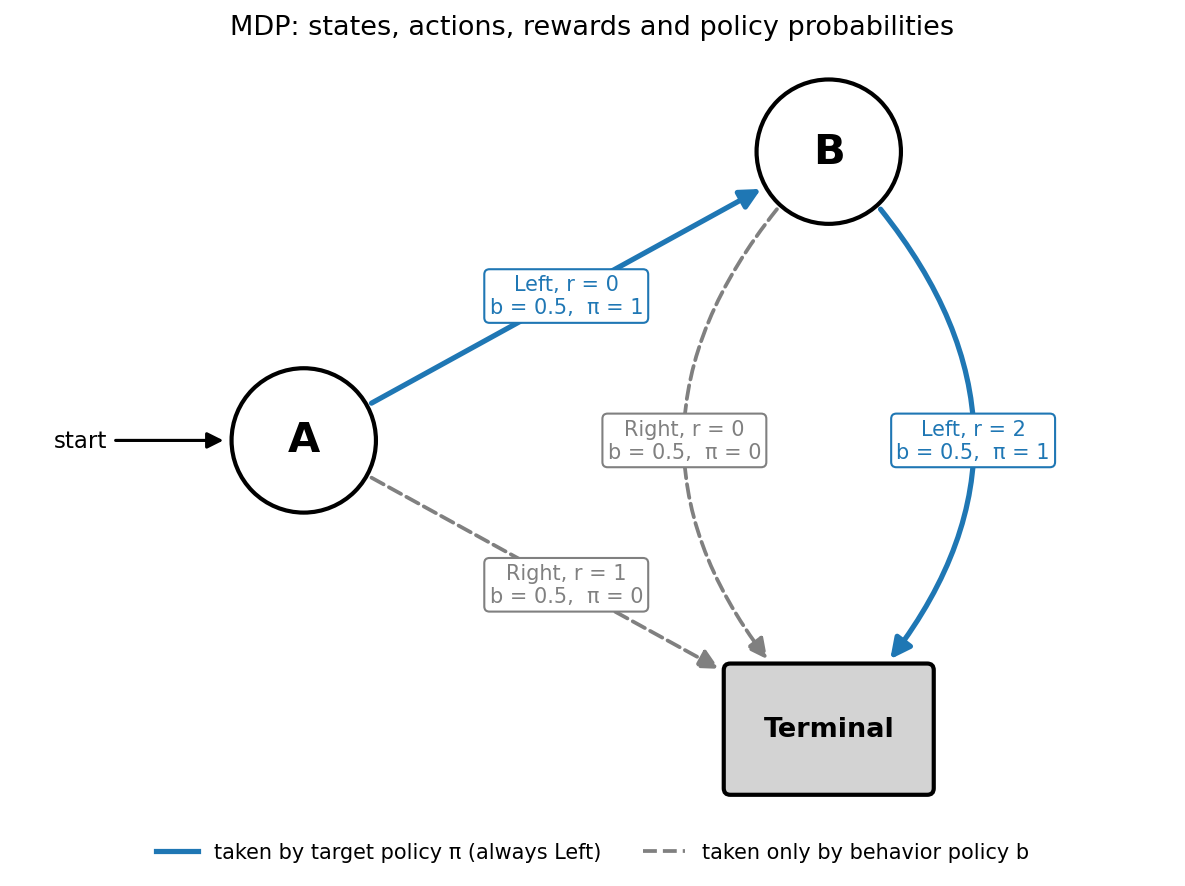

In [ ]:
# draw the MDP (code in visualize_mdp.py) and show it inline
from IPython.display import Image, display
from visualize_mdp import plot_mdp

plot_mdp(os.path.join(FIGURES_DIR, "mdp_diagram.png"))
display(Image(os.path.join(FIGURES_DIR, "mdp_diagram.png"), width=520))

## Part 1: Generate 10,000 episodes

In [ ]:
# sample N episodes from the behavior policy b (seed for reproducibility)
N_EPISODES = 10_000
SEED = 0
TRUE_V_A = 2.0  # v_pi(A): pi goes A -Left-> B -Left-> Terminal, return 0 + 2

random.seed(SEED)
episodes = [generate_episode() for _ in range(N_EPISODES)]

print(f"Generated {len(episodes)} episodes")
for i, ep in enumerate(episodes[:5]):
    print(f"  episode {i}: {ep}")

# only three trajectories exist; check their frequencies against b (0.50 / 0.25 / 0.25)
counts = Counter(tuple((s, a) for s, a, _ in ep) for ep in episodes)
for traj, c in counts.most_common():
    print(f"  {str(traj):<38} {c:>5}  ({c / N_EPISODES:.4f})")

Generated 10000 episodes
  episode 0: [('A', 'Right', 1)]
  episode 1: [('A', 'Right', 1)]
  episode 2: [('A', 'Left', 0), ('B', 'Left', 2)]
  episode 3: [('A', 'Right', 1)]
  episode 4: [('A', 'Left', 0), ('B', 'Right', 0)]
  (('A', 'Right'),)                       5033  (0.5033)
  (('A', 'Left'), ('B', 'Left'))          2492  (0.2492)
  (('A', 'Left'), ('B', 'Right'))         2475  (0.2475)


## Part 2: Total return $G$ of every episode

In [ ]:
# G = R_1 + gamma R_2 + ... ; gamma = 1 (undiscounted, episodic task)
GAMMA = 1.0


def episode_return(episode, gamma=GAMMA):
    G = 0.0
    for _, _, reward in reversed(episode):
        G = reward + gamma * G
    return G


returns = np.array([episode_return(ep) for ep in episodes])

print("Returns of the first 5 episodes:", returns[:5])
print("Distribution of G:", dict(sorted(Counter(returns.tolist()).items())))
print(f"Mean return under b (on-policy estimate of v_b(A)): {returns.mean():.4f}  (exact 1.0)")

Returns of the first 5 episodes: [1. 1. 2. 1. 0.]
Distribution of G: {0.0: 2475, 1.0: 5033, 2.0: 2492}
Mean return under b (on-policy estimate of v_b(A)): 1.0017  (exact 1.0)


## Part 3: Importance sampling ratio $\rho = \prod_t \pi(A_t|S_t) / b(A_t|S_t)$

In [ ]:
# product of per-step policy ratios over the whole episode (hint from the assignment)
def importance_ratio(episode):
    rho = 1.0
    for state, action, reward in episode:
        rho *= target_policy[state][action] / behavior_policy[state][action]
    return rho


rhos = np.array([importance_ratio(ep) for ep in episodes])

print("rho of the first 5 episodes:", rhos[:5])
print("Distribution of rho:", dict(sorted(Counter(rhos.tolist()).items())))
# only Left,Left matches pi: rho = (1/0.5) * (1/0.5) = 4; any Right gives rho = 0

rho of the first 5 episodes: [0. 0. 4. 0. 0.]
Distribution of rho: {0.0: 7508, 4.0: 2492}


## Part 4: Ordinary importance sampling, $V(A) = \frac{1}{N}\sum_i \rho_i G_i$

In [ ]:
# every episode starts in A and visits it once, so each episode gives one return for V(A)
def ordinary_is(rhos, returns):
    return np.mean(rhos * returns)


V_ois = ordinary_is(rhos, returns)
print(f"Ordinary IS estimate of V(A): {V_ois:.4f}   (true v_pi(A) = {TRUE_V_A})")

Ordinary IS estimate of V(A): 1.9936   (true v_pi(A) = 2.0)


## Part 5: Weighted importance sampling, $V(A) = \frac{\sum_i \rho_i G_i}{\sum_i \rho_i}$

In [ ]:
# normalise by the total weight instead of N (0 if no episode matches pi)
def weighted_is(rhos, returns):
    total_weight = rhos.sum()
    return (rhos * returns).sum() / total_weight if total_weight > 0 else 0.0


V_wis = weighted_is(rhos, returns)
print(f"Weighted IS estimate of V(A): {V_wis:.4f}   (true v_pi(A) = {TRUE_V_A})")

Weighted IS estimate of V(A): 2.0000   (true v_pi(A) = 2.0)


## Part 6: Repeat the experiment 20 times; mean and standard deviation

In [ ]:
# each experiment = fresh batch of 10,000 episodes -> one OIS and one WIS estimate
N_EXPERIMENTS = 20


def run_experiment(n_episodes=N_EPISODES):
    eps = [generate_episode() for _ in range(n_episodes)]
    G = np.array([episode_return(ep) for ep in eps])
    rho = np.array([importance_ratio(ep) for ep in eps])
    return ordinary_is(rho, G), weighted_is(rho, G)


ois_estimates, wis_estimates = [], []
for k in range(1, N_EXPERIMENTS + 1):
    random.seed(SEED + k)  # distinct, reproducible seed per experiment
    ois, wis = run_experiment()
    ois_estimates.append(ois)
    wis_estimates.append(wis)
ois_estimates, wis_estimates = np.array(ois_estimates), np.array(wis_estimates)

print(f"{'exp':>4} {'ordinary IS':>12} {'weighted IS':>12}")
for k, (o, w) in enumerate(zip(ois_estimates, wis_estimates), start=1):
    print(f"{k:>4} {o:>12.4f} {w:>12.4f}")

# sample standard deviation (ddof=1) across the 20 experiments
print(f"\n{'':>4} {'mean':>12} {'std':>12} {'bias':>12}")
for name, est in [("OIS", ois_estimates), ("WIS", wis_estimates)]:
    print(f"{name:>4} {est.mean():>12.4f} {est.std(ddof=1):>12.4f} {est.mean() - TRUE_V_A:>12.4f}")

# theory check for OIS: rho*G = 8 w.p. 0.25 else 0 -> Var = 64*0.25 - 2^2 = 12
print(f"\nTheoretical OIS std for N={N_EPISODES}: sqrt(12/N) = {np.sqrt(12 / N_EPISODES):.4f}")

 exp  ordinary IS  weighted IS
   1       2.0040       2.0000
   2       2.0272       2.0000
   3       1.9744       2.0000
   4       2.0768       2.0000
   5       2.0152       2.0000
   6       2.0016       2.0000
   7       2.0264       2.0000
   8       2.0912       2.0000
   9       1.9984       2.0000
  10       2.0432       2.0000
  11       2.0432       2.0000
  12       2.0024       2.0000
  13       2.0232       2.0000
  14       1.9648       2.0000
  15       2.0048       2.0000
  16       2.0000       2.0000
  17       2.0056       2.0000
  18       1.9968       2.0000
  19       2.0128       2.0000
  20       1.9800       2.0000

             mean          std         bias
 OIS       2.0146       0.0312       0.0146
 WIS       2.0000       0.0000       0.0000

Theoretical OIS std for N=10000: sqrt(12/N) = 0.0346


## Part 7: Estimates vs experiment number

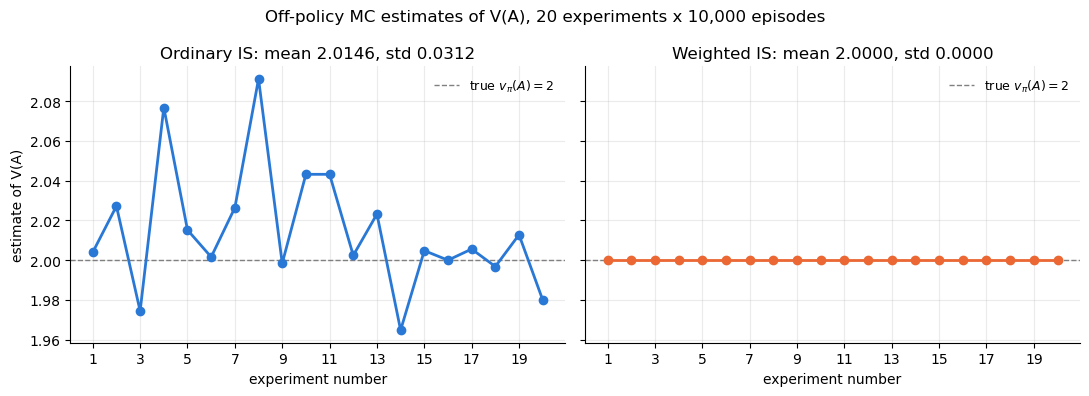

In [ ]:
# same y-axis on both panels so the spread of the two estimators is directly comparable
OIS_COLOR, WIS_COLOR = "#2a78d6", "#eb6834"
exp_ids = np.arange(1, N_EXPERIMENTS + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, est, color, name in [(axes[0], ois_estimates, OIS_COLOR, "Ordinary IS"),
                             (axes[1], wis_estimates, WIS_COLOR, "Weighted IS")]:
    ax.axhline(TRUE_V_A, color="gray", ls="--", lw=1, label=r"true $v_\pi(A) = 2$")
    ax.plot(exp_ids, est, color=color, lw=2, marker="o", ms=6)
    ax.legend(loc="upper right", frameon=False, fontsize=9)
    ax.set_title(f"{name}: mean {est.mean():.4f}, std {est.std(ddof=1):.4f}")
    ax.set_xlabel("experiment number")
    ax.set_xticks(exp_ids[::2])
    ax.grid(alpha=0.25)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("estimate of V(A)")
fig.suptitle(f"Off-policy MC estimates of V(A), {N_EXPERIMENTS} experiments x {N_EPISODES:,} episodes")
fig.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "is_estimates_vs_experiment.png"), dpi=150)
plt.show()

Showing convergence over the running estimates over the 10000 episodes (part 1)

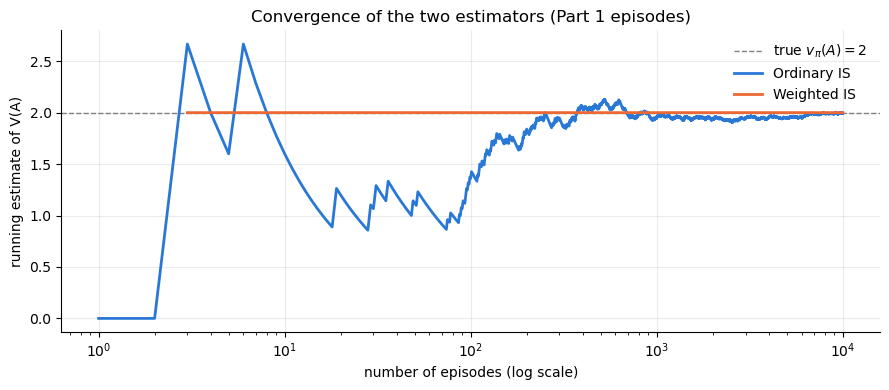

In [ ]:
# running estimate after n episodes: OIS = cumsum(rho G) / n, WIS = cumsum(rho G) / cumsum(rho)
n = np.arange(1, N_EPISODES + 1)
cum_rG, cum_rho = np.cumsum(rhos * returns), np.cumsum(rhos)
running_ois = cum_rG / n
running_wis = np.where(cum_rho > 0, cum_rG / np.where(cum_rho > 0, cum_rho, 1), np.nan)

fig, ax = plt.subplots(figsize=(9, 4))
ax.axhline(TRUE_V_A, color="gray", ls="--", lw=1, label=r"true $v_\pi(A) = 2$")
ax.plot(n, running_ois, color=OIS_COLOR, lw=2, label="Ordinary IS")
ax.plot(n, running_wis, color=WIS_COLOR, lw=2, label="Weighted IS")
ax.set_xscale("log")
ax.set_xlabel("number of episodes (log scale)")
ax.set_ylabel("running estimate of V(A)")
ax.set_title("Convergence of the two estimators (Part 1 episodes)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "is_convergence.png"), dpi=150)
plt.show()

## Part 8: Conceptual questions

**Q1. Why is importance sampling necessary?**
The episodes come from $b$, not $\pi$, so a plain average of their returns estimates $v_b(A)$: here it is $\approx 1.00$ (Part 2), not $v_\pi(A) = 2$.
Importance sampling reweights each return by how much more or less likely its trajectory is under $\pi$ than under $b$, which makes $\mathbb{E}_b[\rho G] = v_\pi(A)$.
This only works under *coverage*: every action $\pi$ might take must have $b(a|s) > 0$.

**Q2. Why can the importance sampling ratio become very large?**
$\rho$ is a *product* of per-step ratios $\pi(a|s)/b(a|s)$. When $b$ rarely picks the action $\pi$ prefers, each ratio is $> 1$, and the product grows exponentially with episode length.
Here each matching step contributes $1/0.5 = 2$, so $\rho = 4$ after two steps; a $T$-step episode would give $2^T$, and a single step with $b(a|s) = 0.01$ would give $100$.
These rare, very large weights are what make ordinary IS high-variance (its variance can even be infinite).

**Q3. Which estimator has smaller variance?**
Weighted IS. Over 20 experiments: WIS std $= 0.0000$ vs OIS std $= 0.0312$ (theory: $\sqrt{12/N} = 0.0346$).
WIS is a weighted *average* of observed returns, so it always lies in $[\min G, \max G]$. In this MDP every episode with $\rho > 0$ has $G = 2$, so WIS is exactly 2 whenever at least one such episode is sampled.
OIS averages $\rho G \in \{0, 8\}$, which has variance $64 \cdot 0.25 - 2^2 = 12$ per episode.

**Q4. Which estimator is unbiased?**
Ordinary IS: $\mathbb{E}_b[\rho G] = \sum_\tau b(\tau)\frac{\pi(\tau)}{b(\tau)} G(\tau) = v_\pi(A)$, here $0.25 \cdot 4 \cdot 2 = 2$.
The 20-run mean of $2.0146$ is within sampling noise (standard error $\approx 0.0346/\sqrt{20} \approx 0.008$).
Weighted IS is **biased**, because it is a ratio of two random sums, but it is consistent: the bias goes to 0 as $N \to \infty$. For example, with a single matching episode WIS returns that episode's $G$ unchanged.
The bias doesn't show here only because every matching return is identical.

**Q5. Why might weighted importance sampling converge faster in practice?**
Normalising by $\sum \rho$ makes WIS a convex combination of returns, so one huge $\rho$ cannot blow up the estimate, and its variance stays bounded when returns are bounded (OIS's variance can be unbounded).
Its bias vanishes as $N$ grows, so in practice its much lower variance dominates and it reaches a good estimate with far fewer episodes.
In the convergence plot, OIS swings between 0 and about 2.7 in the first ~100 episodes and is still off by a few hundredths after 1,000. WIS sits at exactly 2 from the first episode whose trajectory $\pi$ would also take (episode 3).